# Print Results

In [7]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import torch
import deepinv as dinv
from deepinv.physics import Denoising, GaussianNoise, PoissonNoise
from deepinv.utils.demo import load_url_image, get_image_url
from deepinv.utils.plotting import plot

from opt_functions.plot_results import *
from opt_functions.Solver_functions.white_opt_pnp import *
        
import ISM.simulation.PSF_sim as ism
import ISM.analysis.Graph_lib as gr

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ipywidgets import interact, SelectMultiple
import pandas as pd
import matplotlib.pyplot as plt


device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

import deepinv as dinv
from pathlib import Path
import gdown
import torch
import wandb
import matplotlib.pyplot as plt
from matplotlib import cm
import torch.nn as nn
from deepinv.loss.metric import SSIM, PSNR


from deepinv.utils.demo import load_dataset, load_degradation
from deepinv.utils.plotting import plot, plot_curves, plot_inset
from huggingface_hub import hf_hub_download


from microssim import MicroSSIM, micro_structural_similarity
from skimage.metrics import structural_similarity


# GRID SEARCH

In [8]:
def load_result(name, flux, loss, fidelity, prior="", optim=None,
                save_dir="Results/results_gridsearch"):
    candidates = []
    if optim is not None:
        # new naming (make_tag): ..._weakly_convex_lossL2_PROJ_GD
        candidates.append(f"Fidelity{fidelity}_{name}_flux{flux}_{prior}_loss{loss}_{optim}")
    # old naming: ..._drunet_lossL2 / ..._drunet_gauss_lossL2
    candidates.append(f"Fidelity{fidelity}_{name}_flux{flux}_drunet_{prior}loss{loss}")

    for tag in candidates:
        path = os.path.join(save_dir, f"best_rec_{tag}.pth")
        if os.path.exists(path):
            return torch.load(path, map_location="cpu", weights_only=False)
    return None

def plot_psnr_vs_flux(df, losses=None, fidelities=None, save_path=None):
    """losses / fidelities: list of names to show, or None to show all."""
    all_losses = sorted(df["loss"].unique())
    losses = losses or all_losses
    fidelities = fidelities or sorted(df["fidelity"].unique())

    missing = set(losses) - set(all_losses)
    if missing:
        print(f"Not in results: {missing}. Available: {all_losses}")

    sel = df[df["loss"].isin(losses) & df["fidelity"].isin(fidelities)]
    datasets = sorted(sel["data"].unique())
    colors = dict(zip(all_losses, plt.cm.tab10.colors))   # same color per loss in every plot
    styles = {"KL": ("o", "-"), "l2": ("s", "--")}

    fig, axes = plt.subplots(1, len(datasets), figsize=(7 * len(datasets), 5),
                             sharey=False, squeeze=False)
    for ax, name in zip(axes[0], datasets):
        for (loss, fid), g in sel[sel["data"] == name].groupby(["loss", "fidelity"]):
            g = g.sort_values("flux")
            marker, ls = styles.get(fid, ("^", ":"))
            ax.plot(g["flux"], g["psnr"], marker=marker, linestyle=ls,
                    color=colors[loss], label=f"{loss} / {fid}")
        ax.set_title(name)
        ax.set_xlabel("flux")
        ax.set_xticks(sorted(sel["flux"].unique()))
        ax.grid(alpha=0.3)

    axes[0][0].set_ylabel("PSNR [dB]")
    axes[0][-1].legend(fontsize=8, ncol=2, title="loss / fidelity")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200)
    plt.show()

def load_gt(name):
    x = torch.load(f"Data/Simul_data/{name}.pth", map_location="cpu")
    return (x / x.max()).squeeze().numpy()

def show_grid(name, rows, fluxes, prior, optim, save_dir, crop=None, error=False, save_path=None):
    """
    rows:   list of (loss, fidelity) pairs, one per row, e.g. [("FFL","KL"), ("FFL","l2")]
    fluxes: list of flux values, one per column
    crop:   (y0, y1, x0, x1) to zoom in, or None for the full image
    error:  if True, show |x_rec - x_gt| instead of the reconstruction
    """
    gt = load_gt(name)
    cut = (lambda a: a[crop[0]:crop[1], crop[2]:crop[3]]) if crop else (lambda a: a)

    # load everything first, so the error maps can share one color scale
    recs = {}
    for loss, fid in rows:
        for f in fluxes:
            r = load_result(name, f, loss, fid, prior, optim, save_dir)
            if r is not None:
                img = r["x_rec"].squeeze().numpy()
                recs[(loss, fid, f)] = (img / img.max(), r)
    vmax_err = max((np.abs(cut(im) - cut(gt)).max() for im, _ in recs.values()), default=1)

    n_r, n_c = len(rows), len(fluxes) + 1
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.6 * n_c, 2.6 * n_r), squeeze=False)

    for i, (loss, fid) in enumerate(rows):
        axes[i, 0].imshow(cut(gt), cmap="hot", vmin=0, vmax=1)
        axes[i, 0].set_title("Ground truth" if i == 0 else "", fontsize=9)
        axes[i, 0].set_ylabel(f"{loss}\n{fid}", fontsize=10)

        for j, f in enumerate(fluxes, start=1):
            ax = axes[i, j]
            if (loss, fid, f) not in recs:
                ax.text(0.5, 0.5, "missing", ha="center", va="center", transform=ax.transAxes)
            else:
                im, r = recs[(loss, fid, f)]
                if error:
                    ax.imshow(np.abs(cut(im) - cut(gt)), cmap="inferno", vmin=0, vmax=vmax_err)
                else:
                    ax.imshow(cut(im), cmap="hot", vmin=0, vmax=1)
                ax.set_title(f"flux {f}\n{r['psnr']:.2f} dB  (σ={r['sigma']:.3g}, it={r['iter']})",
                             fontsize=8)

    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(f"{name}_{prior}{'  |  error |x̂ − x|' if error else ''}", fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200)
    plt.show()




In [4]:
save_dir = "Results/results_gridsearch"

# prior = 'gauss_' # not finetuned
prior = 'weakly_convex'
# prior = '' # finetuned
pxsizex = 40
Nx = 256
Nz = 1
optim = "PROJ_GD"

r = load_result("tub_level", 20, "L2", "l2", prior, optim, save_dir)

# print(f"sigma = {r['sigma']:.4f}, iter = {r['iter']}, lambda = {r['lambda']}, PSNR = {r['psnr']:.2f} dB")
gr.ShowImg(r["x_rec"], pxsize_x=pxsizex)
dinv.utils.plotting.plot_curves(r["metrics"])

# pm = r["psnr_map"].numpy()
# plt.imshow(pm, aspect="auto", origin="lower", cmap="viridis")
# plt.xticks(range(len(r["iter_grid"])), r["iter_grid"].tolist(), rotation=60)
# plt.yticks(range(len(r["sigma_grid"])), [f"{s:.3g}" for s in r["sigma_grid"].tolist()])
# plt.xlabel("max_iter"); plt.ylabel("sigma"); plt.colorbar(label="PSNR [dB]")
# plt.title(f"{r['name']}, flux {r['flux']}, {r['loss']}, {r['fidelity']}")
# plt.show()


df = pd.read_csv("Results/results_gridsearch/summary_notft.csv")

# PSNR table: one row per (data, flux), one column per (loss, fidelity)
table = df.pivot_table(index=["data", "flux"], columns=["loss", "fidelity"], values="psnr")
print(table.round(2))

# Best configuration for each (data, flux)
print(df.loc[df.groupby(["data", "flux"])["psnr"].idxmax()])
# %%

plot_psnr_vs_flux(df, losses=["FFL"])                    # one loss, KL vs l2
plot_psnr_vs_flux(df, losses=["L2"])           # compare two losses
plot_psnr_vs_flux(df, losses=["L1"])
plot_psnr_vs_flux(df, losses=["L1_FFL"])
plot_psnr_vs_flux(df, losses=["L2_FFL"])

fluxes = [5, 10, 20, 40, 60]
losses = ['L2']

# 1) All losses with KL, full image
# show_grid("tub_level", [(l, "l2") for l in losses], fluxes)

# 2) Zoom into a detailed region (choose the coordinates by looking at the GT)
# show_grid("tub_level", [(l, "l2") for l in losses], fluxes, crop=(80, 160, 60, 140))

# 3) Same, as error maps: shows where each loss fails
# show_grid("tub_level", [(l, "KL") for l in losses], fluxes, crop=(80, 160, 60, 140), error=True)

# 4) KL vs l2 for a single loss, to isolate the effect of the likelihood
show_grid("tub_level", [("L2", "KL"), ("L2", "l2")], fluxes, prior, optim, save_dir)

TypeError: 'NoneType' object is not subscriptable

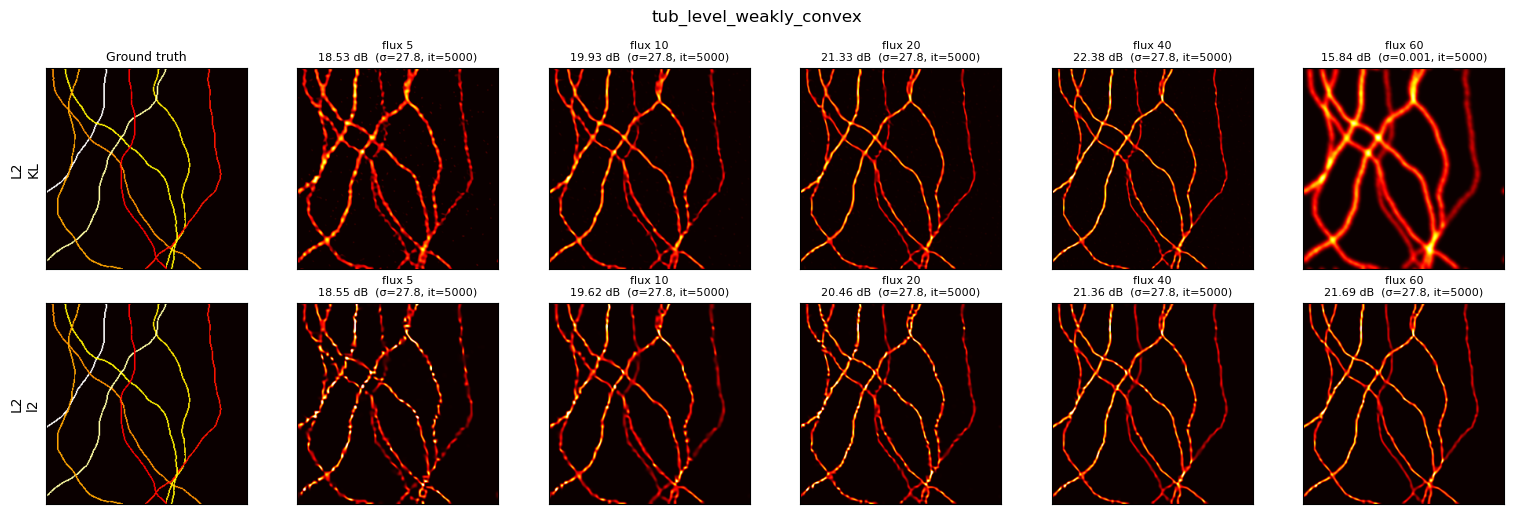

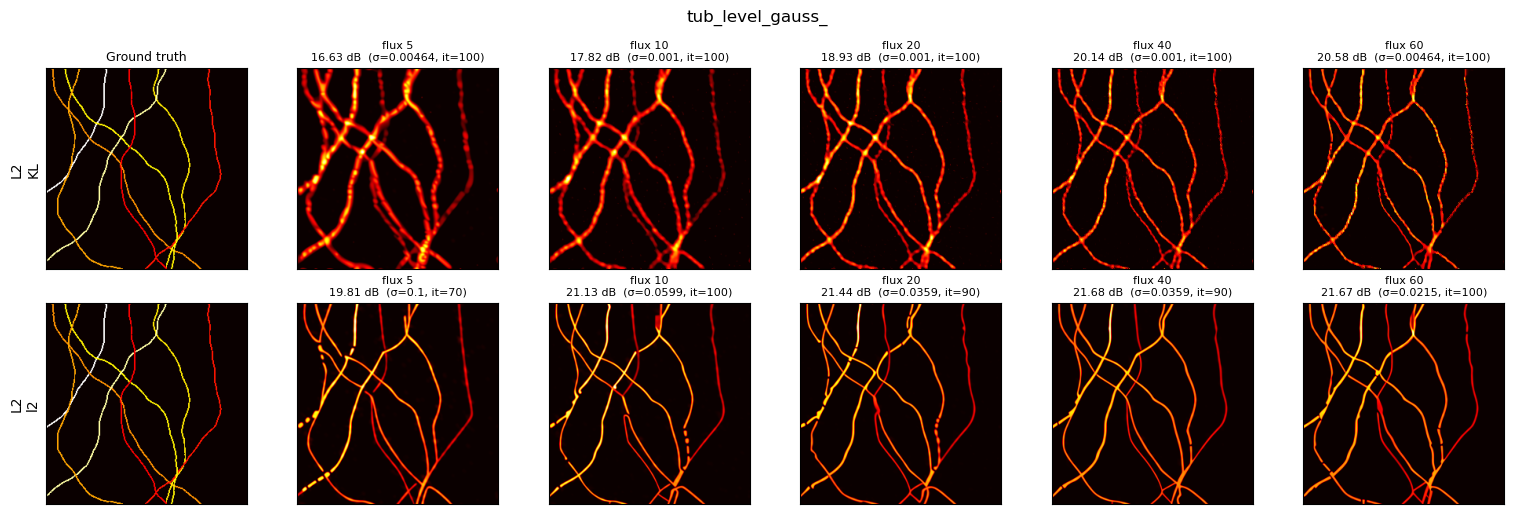

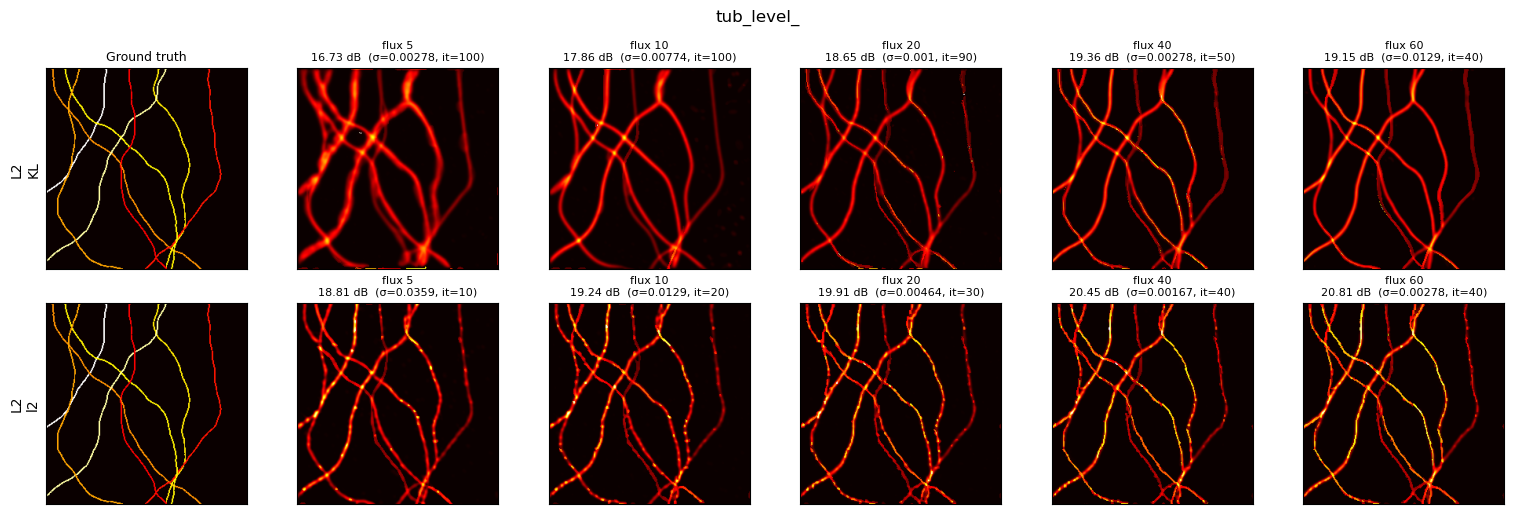

In [13]:
save_dir = "Results/results_gridsearch"

prior = 'gauss_'          # not finetuned
# prior = 'weakly_convex'   # weakly convex 
# prior = ''                  # finetuned
pxsizex = 40
Nx = 256
Nz = 1
optim = "PROJ_GD"
fluxes = [5, 10, 20, 40, 60]
losses = ['L2']
show_grid("tub_level", [("L2", "KL"), ("L2", "l2")], fluxes, 'weakly_convex', optim, save_dir)
show_grid("tub_level", [("L2", "KL"), ("L2", "l2")], fluxes, 'gauss_', optim, save_dir)
show_grid("tub_level", [("L2", "KL"), ("L2", "l2")], fluxes, '', optim, save_dir)

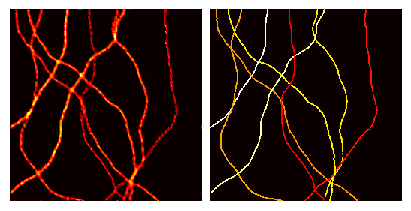

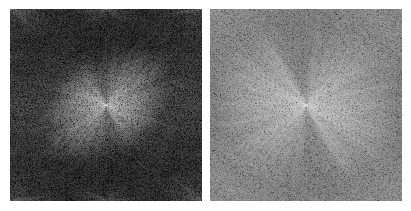

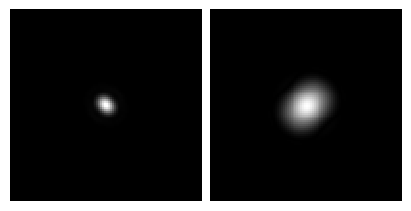

In [50]:
#%%

save_dir = "Results/results_gridsearch"

prior = 'gauss_' # not finetuned
# prior = 'weakly_convex'
# prior = '' # finetuned
pxsizex = 40
Nx = 256
Nz = 1
optim = "PROJ_GD"
LOSS = 'L2'
FIDELITY = 'KL'
flux = 40

r = load_result("tub_level", flux, LOSS, FIDELITY, prior, optim, save_dir)
gt = load_gt("tub_level")
flux = 250
x = r['x_rec']
MEAS_KEYS = ("PSF", "y", "avg_y", "sum_y", "finger_print", "physics",
             "df_kl", "df_l2", "L_kl", "L_l2")
out = generate_meas_ism(torch.tensor(gt), Nx, Nz, pxsizex, flux, device)
meas = dict(zip(MEAS_KEYS, out))
y = meas['y'].unsqueeze(0).unsqueeze(0)
psf = meas['PSF'].sum(0)
def fft_image(img):
    # Porta il tensore a 2D (rimuove dimensioni batch/canale di taglia 1)
    img = img.squeeze()
    # FFT 2D sulle ultime due dimensioni, con la frequenza zero centrata
    F = torch.fft.fftshift(torch.fft.fft2(img), dim=(-2, -1))
    # Log del modulo per rendere visibile la dinamica dello spettro
    return torch.log1p(torch.abs(F)).detach().cpu()

X_f = fft_image(x).unsqueeze(0).unsqueeze(0)
Y_f = fft_image(y).unsqueeze(0).unsqueeze(0)
otf = fft_image(psf).unsqueeze(0).unsqueeze(0)

plot([x, y], cmap = 'hot')
plot([X_f, Y_f])
plot([psf, otf])

# %%

